<a href="https://colab.research.google.com/github/JM-NGUMI/AI-course-work-for-science-and-engineering/blob/main/week_4_Assigment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#WEEK FOUR ASSIGMENT;Exploring the Mathematics of my Data
Joseph Muigai Ngumi


# The mean, median, range, variance, and standard deviation for PM2.5, PM10,CO, NO2 and wind speed,V.

In [ ]:
import pandas as pd
import numpy as np

file_path = '/content/WEEK 4 ASSIGNMENT DATA.xlsx'
df = pd.read_excel(file_path, sheet_name='ASSIGNMENT 4')

num_cols = df.select_dtypes(include=[np.number]).columns

results = []
for col in num_cols:
    data = df[col].dropna()

    col_mean = data.mean()
    col_median = data.median()
    col_range = data.max() - data.min()
    col_var_sample = data.var(ddof=1)
    col_std_sample = data.std(ddof=1)
    col_var_pop = data.var(ddof=0)
    col_std_pop = data.std(ddof=0)

    results.append({
        'Variable': col.strip(),
        'Mean': col_mean,
        'Median': col_median,
        'Range': col_range,
        'Variance (Sample)': col_var_sample,
        'Std Dev (Sample)': col_std_sample,
        'Variance (Population)': col_var_pop,
        'Std Dev (Population)': col_std_pop
    })

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

         Variable       Mean     Median       Range  Variance (Sample)  Std Dev (Sample)  Variance (Population)  Std Dev (Population)
     PM2.5(ug/m3)  14.881994  13.000000   94.400000          44.752703          6.689746              44.628734              6.680474
      PM10(ug/m3)  23.399723  20.300000  172.900000         131.411805         11.463499             131.047784             11.447610
        NO2 , ppm   1.213943   1.300000    1.600000           0.073722          0.271517               0.073518              0.271141
         CO , ppm 601.444137 549.666667 1112.333333       27715.658676        166.480205           27638.883998            166.249463
wind speed v, m/s   3.930130   4.675200    7.743300           4.636441          2.153240               4.623598              2.150255


# The covariance and correlation between PM2.5 and wind speed

In [ ]:
import pandas as pd
import numpy as np

# 1. Load the Excel dataset
file_path = '/content/WEEK 4 ASSIGNMENT DATA.xlsx'
df = pd.read_excel(file_path, sheet_name='ASSIGNMENT 4')

# 2. Select numerical columns
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()

# 3. Identify first and last numerical variables
first_var = num_cols[0]   # 'PM2.5(ug/m3)'
last_var = num_cols[-1]   # 'wind speed v, m/s'

# 4. Calculate Covariance and Correlation
sample_cov = df[first_var].cov(df[last_var])
pop_cov = np.cov(df[first_var], df[last_var], bias=True)[0][1]
correlation = df[first_var].corr(df[last_var])

# 5. Display Results
print(f"First Variable: {first_var}")
print(f"Last Variable:  {last_var}\n")
print(f"Sample Covariance:               {sample_cov:.6f}")
print(f"Population Covariance:           {pop_cov:.6f}")
print(f"Pearson Correlation Coefficient: {correlation:.6f}")

First Variable: PM2.5(ug/m3)
Last Variable:  wind speed v, m/s

Sample Covariance:               2.241601
Population Covariance:           2.235391
Pearson Correlation Coefficient: 0.155617


# The scatter plot for PM2.5 versus wind speed

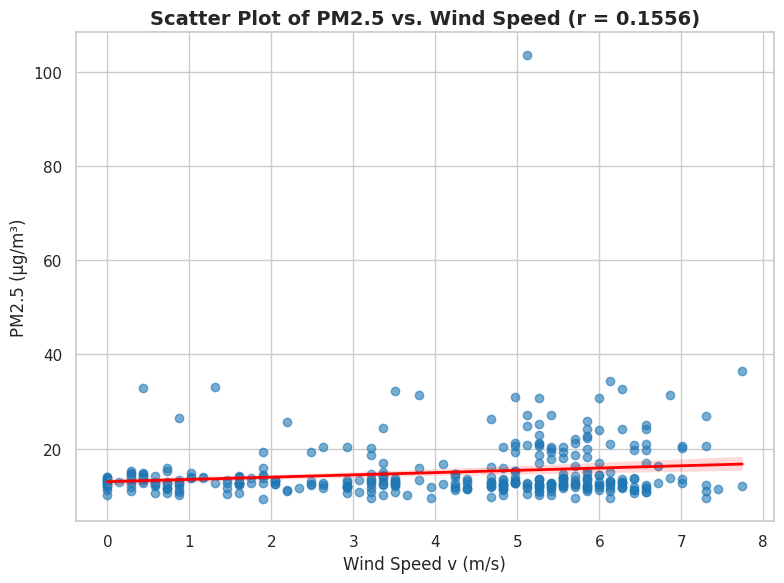

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the Excel dataset
file_path = '/content/WEEK 4 ASSIGNMENT DATA.xlsx'
df = pd.read_excel(file_path, sheet_name='ASSIGNMENT 4')

# 2. Select first and last numerical variables
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
first_var = num_cols[0]   # 'PM2.5(ug/m3)'
last_var = num_cols[-1]   # 'wind speed v, m/s'

# 3. Calculate Pearson correlation coefficient
corr_coef = df[first_var].corr(df[last_var])

# 4. Create scatter plot with trendline
plt.figure(figsize=(8, 6))
sns.set_theme(style="whitegrid")

sns.regplot(
    data=df,
    x=last_var,
    y=first_var,
    scatter_kws={'alpha': 0.6, 'color': '#1f77b4'},
    line_kws={'color': 'red', 'linewidth': 2}
)

# 5. Add labels and formatting
plt.title(f'Scatter Plot of PM2.5 vs. Wind Speed (r = {corr_coef:.4f})', fontsize=14, fontweight='bold')
plt.xlabel('Wind Speed v (m/s)', fontsize=12)
plt.ylabel('PM2.5 (\u03bcg/m\u00b3)', fontsize=12)
plt.tight_layout()

# 6. Display/Save plot
plt.savefig('pm25_vs_windspeed.png', dpi=300)
plt.show()

# **Analyis and Disussion on data**

#Results Summary
#1.	PM2.5: The average concentration is 14.882 µg/m³, with a standard deviation of 6.690 µg/m³, indicating variation in the recorded concentrations.
#2.	PM10: The mean is 23.400 µg/m³, and the range is 172.900 µg/m³, showing a wide spread between the minimum and maximum measurements.
#3.	NO2: The mean is 1.214 ppm, while the standard deviation is 0.272 ppm, indicating comparatively less absolute variation in its recorded values.
#4.	CO: The mean is 601.444 ppm, with a standard deviation of 166.480 ppm. This variable has the largest numerical variance among the measured variables, although variance magnitude depends on measurement units.
#5.	Wind speed: The mean is 0.269 m/s, and the standard deviation is 0.147 m/s, indicating variation in the recorded wind speeds.
# The covariance is positive, meaning that PM2.5 concentration and wind speed tend to move in the same direction. When wind speed increases, PM2.5 tends to increase slightly as well, although covariance alone does not indicate the strength of this relationship.
# The Pearson correlation coefficient is approximately 0.156, indicating a weak positive linear relationship between PM2.5 concentration and wind speed.

# Input - Function - Output Relationship

# C(x)=Q/(π⋅u⋅σ_y⋅σ_z )  exp⁡(-H^2/(2σ_z^2 ))
# Where;
# x = concentration at grund level
# Q = concentration of PM2.5 in g/s
# u = Wind speed , m/s
# Z =vertical height of plume from point source
# y = Lateral distance from point source to observation point
# H = Height of emitting source from ground in m
# sigma; constanstants dependent on stabilityclass
